# Remaining Useful Life (RUL) Prediction of Turbofan Jet Engines
### NASA C-MAPSS Dataset (FD001 - FD004)

**Name:** Dibyendu Maity
**ID:** B2630039
**Course:** M.Sc Data Science, RKMVERI Belur
**Project:** Machine Learning project, Semester 1

**Goal:** Using the sensor readings of an engine, predict how many more flight cycles it can run before it fails (its Remaining Useful Life, RUL).

# 0. Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# %pip install jinja2      # needed once for the coloured tables (.style)

# 1. Loading the Data

## 1.1 Column names
Every file has 26 columns: engine number, cycle number, 3 operating settings and 21 sensors.

In [2]:
# ===== 1.1 column names =====
column_names = ["unit", "cycle", "op1", "op2", "op3"] + ['s{}'.format(i) for i in range(1, 22)]

FDS = ["FD001", "FD002", "FD003", "FD004"]
op_cols = ["op1", "op2", "op3"]
sensor_cols = [f"s{i}" for i in range(1, 22)]

## 1.2 Functions to load train and test
- **Train:** every engine runs till failure, so RUL = last cycle - current cycle.
- **Test:** every engine is stopped before failure. The `RUL_FDxxx.txt` file gives the true RUL at the last observed cycle, so RUL = (last cycle + final RUL) - current cycle.

In [3]:
# ===== 1.2 load functions =====
def load_train(fd, folder):
    train = pd.read_csv(f"{folder}/train_{fd}.txt", sep=r"\s+", header=None, names=column_names)
    train["max_cycle"] = train.groupby("unit")["cycle"].transform("max")
    train["RUL"] = train["max_cycle"] - train["cycle"]
    train.drop("max_cycle", axis=1, inplace=True)
    return train

In [4]:
def load_test(fd, folder):

    # B1: load test sensor data
    test = pd.read_csv(f"{folder}/test_{fd}.txt", sep=r"\s+", header=None, names=column_names)

    # B2: load the answer file
    rul_df = pd.read_csv(f"{folder}/RUL_{fd}.txt", header=None, names=["final_RUL"])

    # B3: give each answer its engine number
    rul_df["unit"] = np.arange(1, len(rul_df) + 1)

    # B4: add max_cycle
    test["max_cycle"] = test.groupby("unit")["cycle"].transform("max")

    # B5: attach the answer to every row
    test = test.merge(rul_df, on="unit")

    # B6: add RUL
    test["RUL"] = (test["max_cycle"] + test["final_RUL"]) - test["cycle"]

    # B7: drop the helper columns
    test = test.drop(columns=["max_cycle", "final_RUL"])

    return test

## 1.3 Load all four datasets

In [ ]:
# ===== 1.3 load FD001 to FD004 =====
folder = r"D:\Programmes\ML_Project\NASA_jet engine" 

train_data = {}
test_data = {}

for fd in FDS:
    train_data[fd] = load_train(fd, folder)
    test_data[fd] = load_test(fd, folder)
    print(fd, "loaded:", train_data[fd].shape, test_data[fd].shape)

FD001 loaded: (20631, 27) (13096, 27)
FD002 loaded: (53759, 27) (33991, 27)
FD003 loaded: (24720, 27) (16596, 27)
FD004 loaded: (61249, 27) (41214, 27)


In [6]:
# start and end of engine 1 (RUL should reach 0 at the end)
display(train_data["FD001"][train_data["FD001"]["unit"] == 1].head())
display(train_data["FD001"][train_data["FD001"]["unit"] == 1].tail())

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,2388.23,8117.69,8.5207,0.03,396,2388,100.0,38.51,22.9588,4
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,2388.33,8117.51,8.5183,0.03,395,2388,100.0,38.48,23.1127,3
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,2388.35,8112.58,8.5223,0.03,398,2388,100.0,38.49,23.0675,2
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,2388.30,8114.61,8.5174,0.03,394,2388,100.0,38.45,23.1295,1
191,1,192,0.0009,-0.0000,100.0,518.67,643.54,1601.41,1427.20,14.62,...,2388.32,8110.93,8.5113,0.03,396,2388,100.0,38.48,22.9649,0


## 1.4 Data quality checks
Basic statistics, missing values, duplicates and cycle gaps.

In [7]:
# ===== 1.4a statistics of settings and sensors (FD001) =====
train_data['FD001'][op_cols + sensor_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
op1,20631.0,-0.000,0.002,-0.009,-0.002,0.000,0.002,0.009
op2,20631.0,0.000,0.000,-0.001,-0.000,0.000,0.000,0.001
op3,20631.0,100.000,0.000,100.000,100.000,100.000,100.000,100.000
s1,20631.0,518.670,0.000,518.670,518.670,518.670,518.670,518.670
s2,20631.0,642.681,0.500,641.210,642.325,642.640,643.000,644.530
s3,20631.0,1590.523,6.131,1571.040,1586.260,1590.100,1594.380,1616.910
s4,20631.0,1408.934,9.001,1382.250,1402.360,1408.040,1414.555,1441.490
s5,20631.0,14.620,0.000,14.620,14.620,14.620,14.620,14.620
s6,20631.0,21.610,0.001,21.600,21.610,21.610,21.610,21.610
s7,20631.0,553.368,0.885,549.850,552.810,553.440,554.010,556.060


In [8]:
# ===== 1.4b missing values, duplicates, cycle continuity =====

# count missing values in ALL datasets
total_missing = 0
for fd in train_data:
    total_missing += train_data[fd].isna().sum().sum()
    total_missing += test_data[fd].isna().sum().sum()
print("Total missing values:", total_missing)

# duplicate rows
for fd in train_data:
    print("Duplicate rows (train {}):".format(fd), train_data[fd].duplicated().sum())

# cycle continuity (all train datasets)
for fd in train_data:
    all_ok = True
    for unit_id, g in train_data[fd].groupby("unit"):
        gaps = g["cycle"].diff().dropna()
        if not (gaps == 1).all():
            all_ok = False
            print("Problem in", fd, "engine", unit_id)
    print(f"Cycle continuity check ({fd}):", all_ok)

Total missing values: 0
Duplicate rows (train FD001): 0
Duplicate rows (train FD002): 0
Duplicate rows (train FD003): 0
Duplicate rows (train FD004): 0
Cycle continuity check (FD001): True
Cycle continuity check (FD002): True
Cycle continuity check (FD003): True
Cycle continuity check (FD004): True


No missing values, no duplicate rows and no missing cycles, so no cleaning is needed.

# 2. Exploratory Data Analysis (EDA)

## 2.1 Engine lifespan distribution
How long does an engine live before failure?

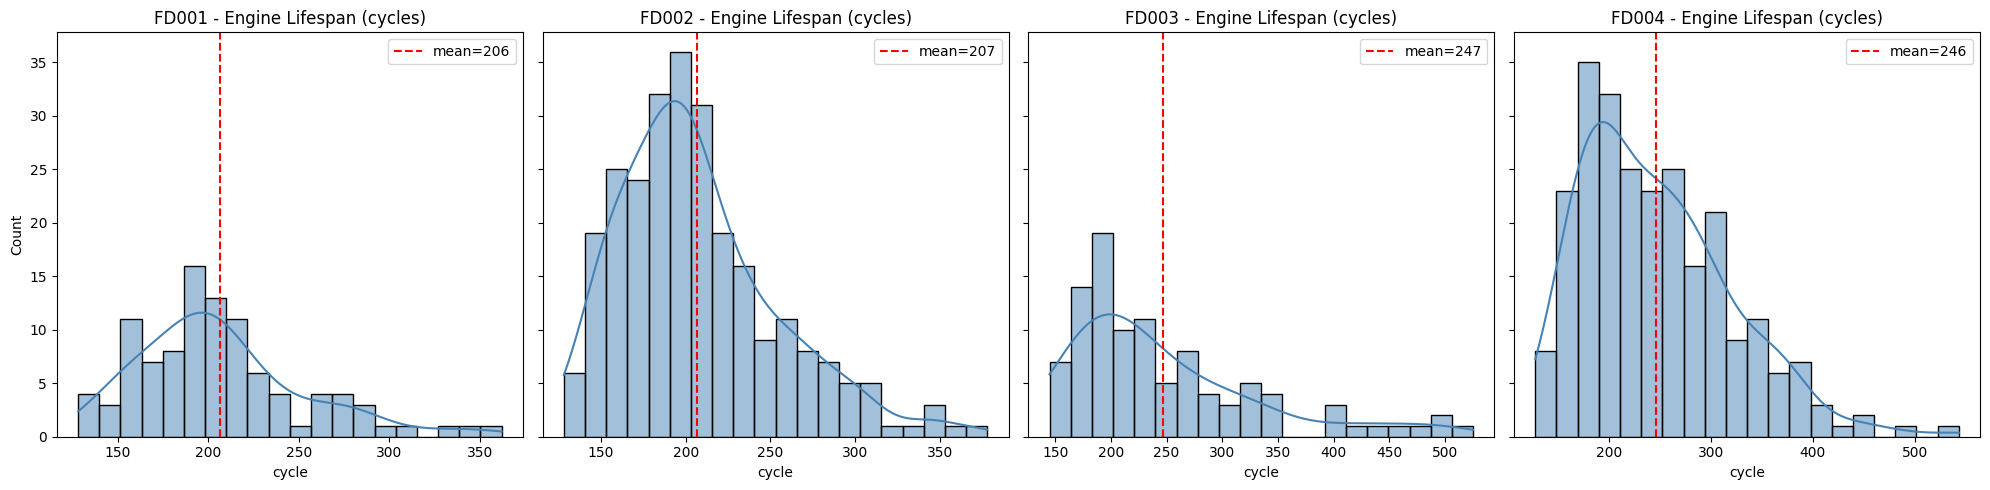

FD001 min: 128 mean: 206.3 max: 362
FD002 min: 128 mean: 206.8 max: 378
FD003 min: 145 mean: 247.2 max: 525
FD004 min: 128 mean: 246.0 max: 543


In [9]:
# ===== 2.1 engine lifespan =====
#fig returns the whole canvas and axes returns the individual subplots.
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)      #subplots(1, 4, figsize=(20, 5), sharey=True) creates a figure with 1 row and 4 columns of subplots, sharing the y-axis.

for ax, fd in zip(axes, FDS):
    life = train_data[fd].groupby("unit")["cycle"].max()            #life holds one number per engine, its lifespan.For FD001 that is 100 numbers.
    sns.histplot(life, bins=20, kde=True, ax=ax, color="steelblue")     #bins specifies no. of bars
    ax.axvline(life.mean(), color="red", ls="--", label=f"mean={life.mean():.0f}")       #it adds a vertical line at the mean
    ax.set_title(f"{fd} - Engine Lifespan (cycles)")
    ax.legend()

plt.tight_layout()          #tight_layout() stops titles and labels from overlapping.
plt.show()

for fd in FDS:
    life = train_data[fd].groupby("unit")["cycle"].max()
    print(fd, "min:", life.min(), "mean:", round(life.mean(), 1), "max:", life.max())

## 2.2 Constant sensors
Some sensors hardly change at all. They carry no information about wear.

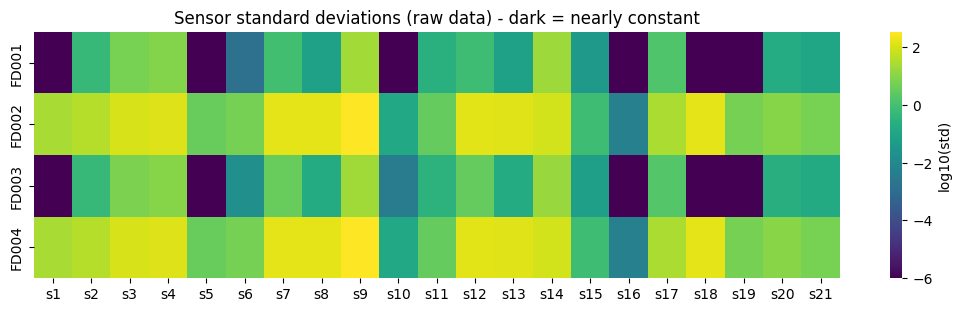

Sensors with std < 1e-3 in FD001: ['s1', 's5', 's10', 's16', 's18', 's19']
Sensors with std < 1e-3 in FD002: []
Sensors with std < 1e-3 in FD003: ['s1', 's5', 's16', 's18', 's19']
Sensors with std < 1e-3 in FD004: []


In [10]:
# ===== 2.2 constant sensors =====
#standard deviation of every sensor, for each dataset
stds = pd.DataFrame({fd: train_data[fd][sensor_cols].std() for fd in FDS})

#heatmap
fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(np.log10(stds.T + 1e-6), cmap="viridis", annot=False, ax=ax, cbar_kws={"label": "log10(std)"})
ax.set_title("Sensor standard deviations (raw data) - dark = nearly constant")
plt.show()

#list of near-constant sensors in each dataset
for fd in FDS:
    print(f"Sensors with std < 1e-3 in {fd}:", stds.index[stds[fd] < 1e-3].tolist())

## 2.3 Operating conditions
**Question:** Do the engines in each dataset all fly under the same conditions, or under different ones?

- op1 is altitude, op2 is Mach number (speed) and op3 is throttle angle. These describe how the engine is being flown, not its health.
- Sensor values change a lot with flying conditions. An engine at high altitude and high speed gives very different temperatures and pressures than one at sea level, even if both are healthy.
- In FD001 and FD003 there is one condition, so sensor changes come from wear.
- In FD002 and FD004 there are six conditions, and the sensors jump between six levels. That jumping is much bigger than the slow wear signal, so it hides it.

A scatter plot of op1 vs op2: if the dots form 6 tight blobs, there are 6 operating conditions. If they form a single blob, there is one.

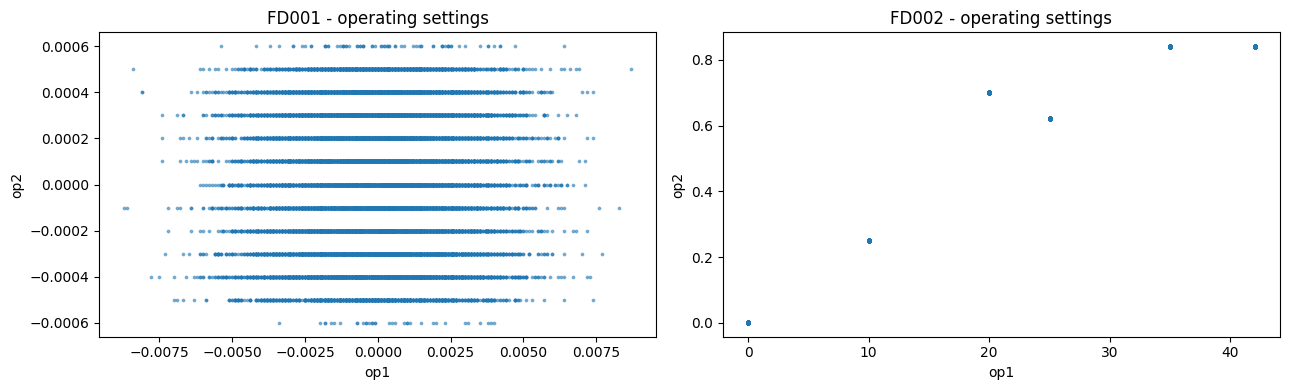

In [11]:
# ===== 2.3 operating settings scatter =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, fd in zip(axes, FDS):
    d = train_data[fd]
    ax.scatter(d["op1"], d["op2"], s=3, alpha=0.5)          #s is the size of the dots, alpha is the transparency of the dots
    ax.set_xlabel("op1")
    ax.set_ylabel("op2")
    ax.set_title(f"{fd} - operating settings")

plt.tight_layout()
plt.show()

FD001 has just one operating condition (the spread is only tiny noise around zero), while FD002 has six distinct operating conditions, so FD002 (and FD004) must be scaled per condition.

## 2.4 Sensor trends over the life of an engine
Which sensors actually change as the engine wears out, and which are just noise?

- **Which sensors to keep:** a sensor that drifts steadily toward failure is useful. One that is a flat noisy band is not.
- **Smoothing may be needed:** if the lines are jagged, noise is large, so averaging over a few cycles will help.
- **The signal is only visible late in life:** lines stay flat early on and bend near failure. This is the reason we later cap RUL at about 125.
- **Engines differ:** each engine starts at a slightly different level.

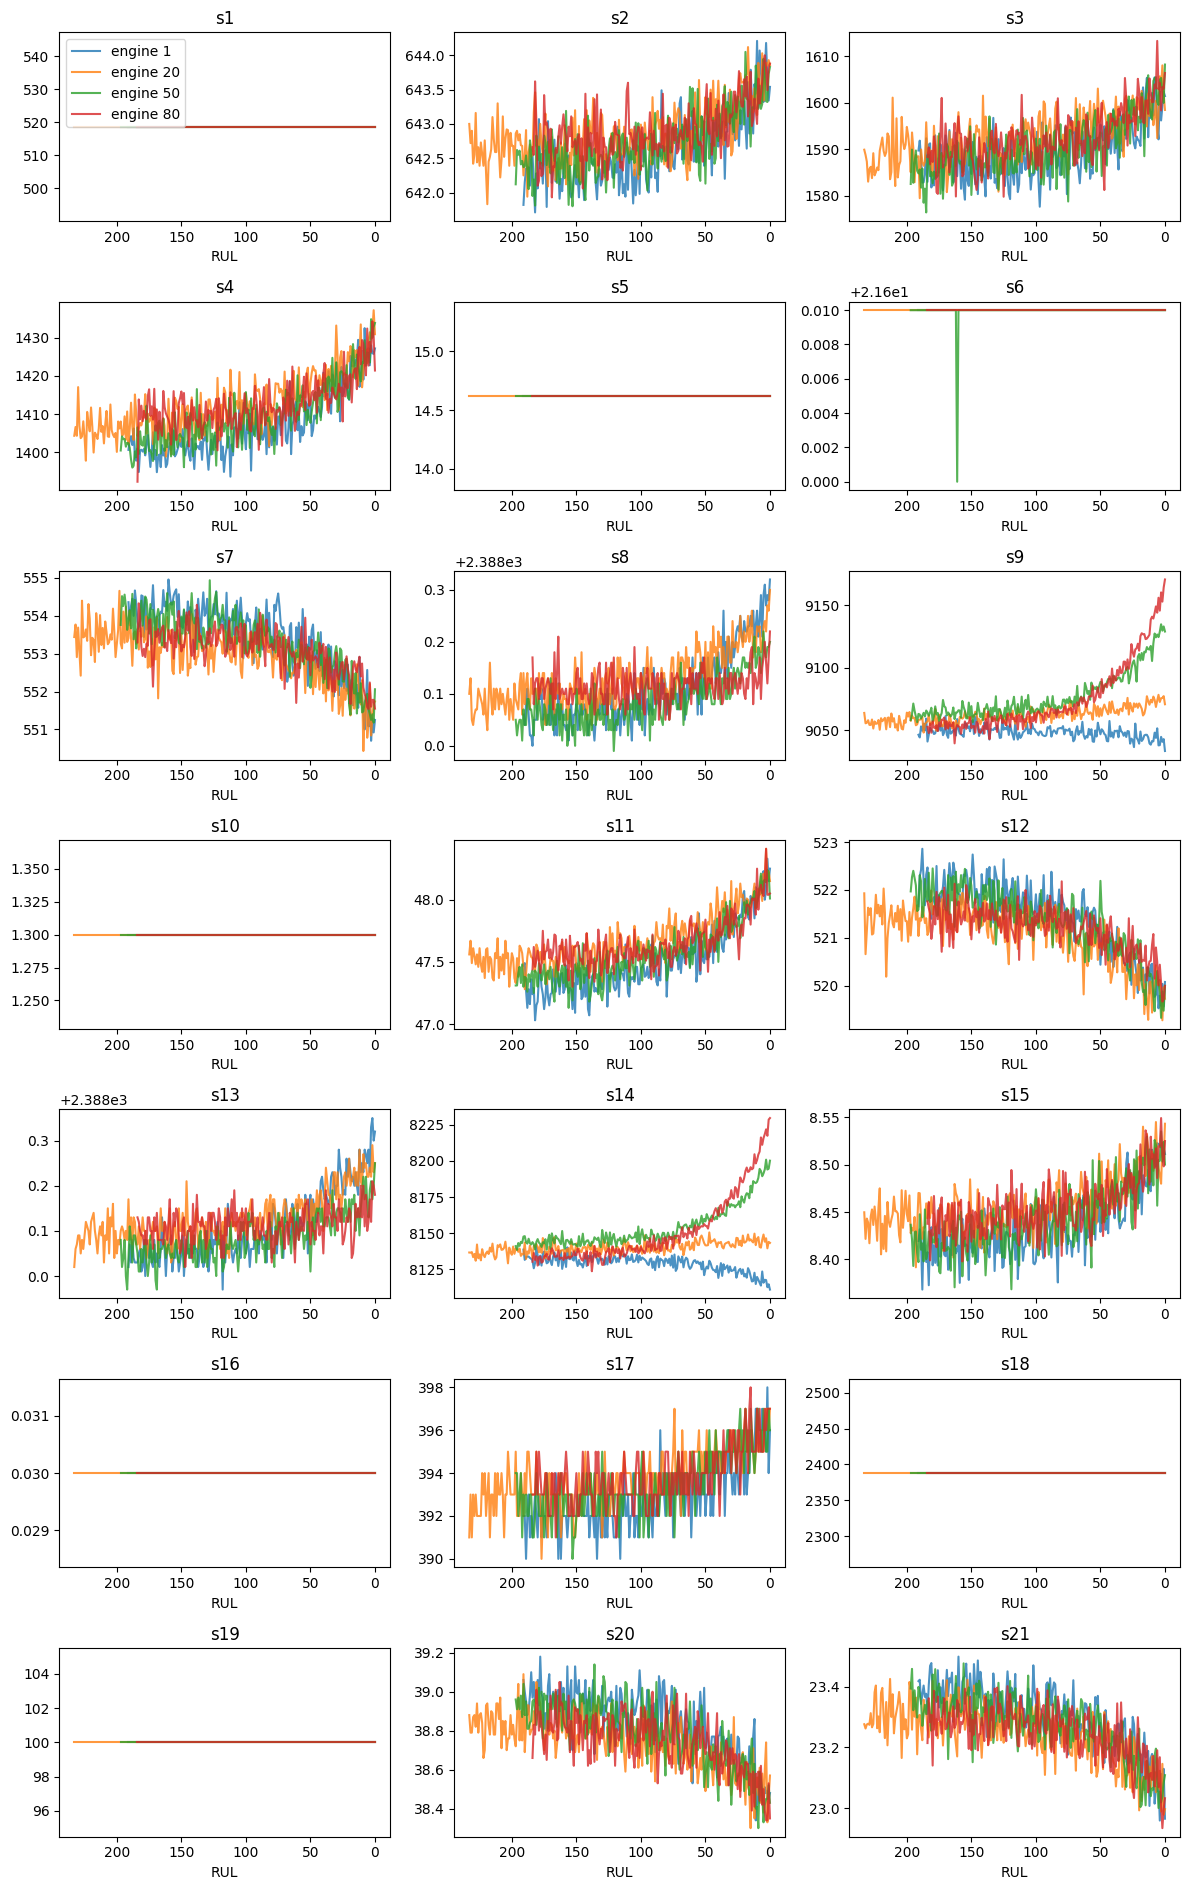

In [12]:
# ===== 2.4 all 21 sensors vs RUL for 4 engines (FD001) =====
show = ['s{}'.format(i) for i in range(1, 22)]
units = [1, 20, 50, 80]

fig, axes = plt.subplots(7, 3, figsize=(12, 19))

for ax, s in zip(axes.ravel(), show):
    for u in units:
        g = train_data["FD001"][train_data["FD001"]["unit"] == u]       #For each of the 4 engines, keep only its rows.  values of sensor
        ax.plot(g["RUL"], g[s], alpha=0.8, label=f"engine {u}")
    ax.invert_xaxis()
    ax.set_title(s)
    ax.set_xlabel("RUL")

axes[0, 0].legend()
plt.tight_layout()
plt.show()

s1, s5, s10, s16, s18 and s19 are straight lines, so they give no information about the remaining life. s9, s14 and s17 are more jagged, which means they have a lot of noise. The useful ones are those which go clearly upward or downward as the RUL goes to 0 (for example s2, s3, s4, s7, s11, s12, s15, s20, s21).

## 2.5 Sensor to RUL correlation (Spearman)
Put a number on how strongly each sensor relates to RUL.

Correlation is a number from -1 to +1:
- +1: when the sensor goes up, RUL always goes up.
- -1: when the sensor goes up, RUL always goes down.
- 0: no relationship.

**Pearson** measures straight-line relationships only. **Spearman** converts values to ranks first, so it measures whether the relationship goes consistently in one direction (monotonic), even if it is curved. Degradation curves are bent (flat, then rising fast), so Spearman fits better.

15 ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
s11   -0.718
s4    -0.702
s15   -0.666
s17   -0.629
s2    -0.629
s3    -0.606
s8    -0.574
s13   -0.573
s9    -0.322
s14   -0.202
s6    -0.128
s20    0.653
s21    0.657
s7     0.679
s12    0.693
Name: RUL, dtype: float64


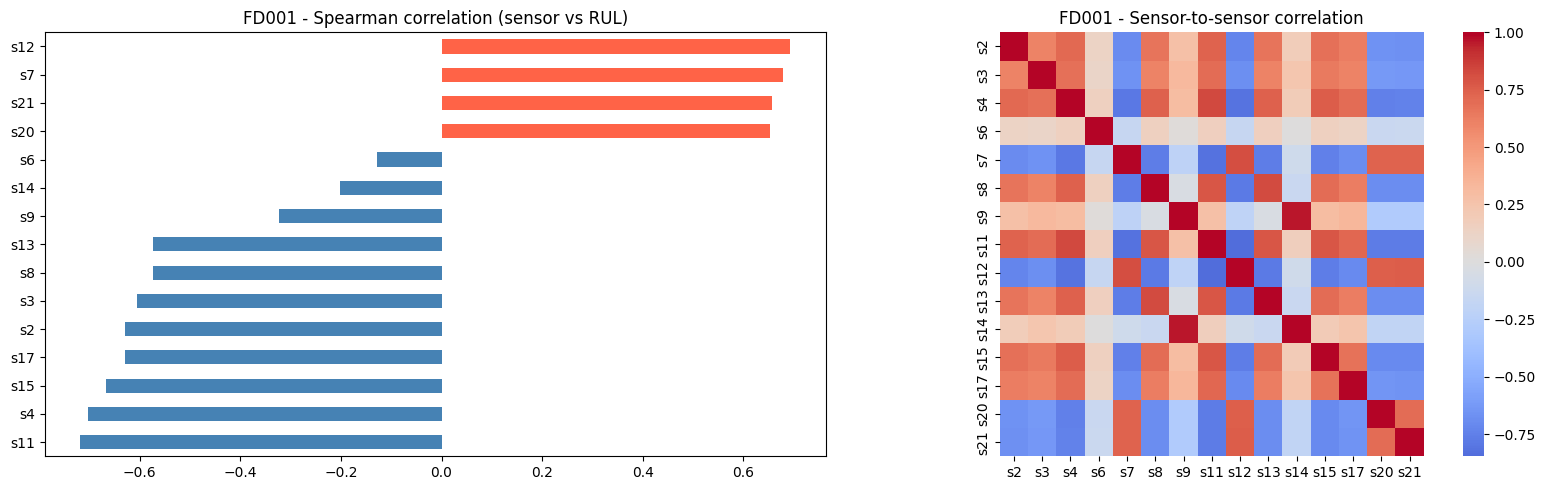

In [13]:
# ===== 2.5 Spearman correlation =====
train1 = train_data["FD001"]

# keep only sensors that actually vary
good = [s for s in sensor_cols if train1[s].std() > 1e-3]
print(len(good), good)

# Spearman correlation of each sensor with RUL
corr_rul = train1[good + ["RUL"]].corr(method="spearman")["RUL"].drop("RUL").sort_values()
print(corr_rul.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# left: bar chart sensor vs RUL
corr_rul.plot.barh(ax=axes[0], color=np.where(corr_rul > 0, "tomato", "steelblue"))
axes[0].set_title("FD001 - Spearman correlation (sensor vs RUL)")

# right: sensor-to-sensor heatmap
sns.heatmap(train1[good].corr(), cmap="coolwarm", center=0, ax=axes[1], square=True)
axes[1].set_title("FD001 - Sensor-to-sensor correlation")

plt.tight_layout()
plt.show()

## 2.6 Health Indicator fitness metrics
In prognostics literature (Coble & Hines), the suitability of a sensor for RUL prediction is measured using three metrics:

- **Monotonicity:** single-direction change over time (close to 1 = good)
- **Trendability:** similarity of the curves across different engines (minimum pairwise correlation)
- **Prognosability:** consistency of the failure values across engines

To suppress noise, each series is smoothed using a 10-cycle moving average. A sensor that does well in all three is easy for a model to learn from.

In [14]:
# ===== 2.6 monotonicity, trendability, prognosability =====
def hi_metrics(df, s, n=100, smooth=10):
    # n = number of points each engine's curve is resampled to (NOT the number of engines)
    # smooth = window size of the moving average

    series, mono, fin, ini = [], [], [], []   # 4 empty lists to collect results per engine

    for u, g in df.groupby("unit"):           # go through one engine at a time
        x = g[s].rolling(smooth, min_periods=1).mean().values
        # smoothed sensor values of this engine as a plain array

        d = np.diff(x)
        # difference between consecutive values: x[1]-x[0], x[2]-x[1], ...
        # positive = went up, negative = went down

        mono.append(abs((d > 0).sum() - (d < 0).sum()) / max(len(d), 1))
        # count of "up" steps minus count of "down" steps, made positive, divided by total steps
        # max(len(d),1) only avoids dividing by zero

        series.append(np.interp(np.linspace(0, 1, n), np.linspace(0, 1, len(x)), x))
        # resample the curve to exactly n=100 points on a 0-to-1 "life" axis,
        # so a 128-cycle engine and a 362-cycle engine can be compared

        fin.append(x[-1]); ini.append(x[0])
        # remember the final value (at failure) and the initial value of this engine

    C = np.corrcoef(np.array(series))
    # 100x100 table: correlation between every pair of engine curves

    fin, ini = np.array(fin), np.array(ini)   # lists -> arrays so we can do maths on them

    return {"monotonicity": np.mean(mono),
            # average monotonicity over all engines
            "trendability": np.nanmin(np.abs(C)),
            # the WORST pair of engines (smallest absolute correlation); nanmin ignores NaN
            "prognosability": np.exp(-np.std(fin) / (np.mean(np.abs(fin - ini)) + 1e-9))}
            # spread of final values divided by how much the sensor typically changed,
            # turned into a 0-to-1 score with exp(-x). 1e-9 avoids division by zero

hi_tbl = pd.DataFrame({s: hi_metrics(train1, s) for s in good}).T
# run hi_metrics for every good sensor -> one column per sensor; .T makes each sensor a row

hi_tbl["average score"] = hi_tbl.mean(axis=1)
# new column: average of the three metrics across each row

hi_tbl = hi_tbl.sort_values("average score", ascending=False)
# best sensors on top

In [15]:
# I have used the `jinja2` package to render HTML and to run the `style` function.
display(hi_tbl.round(3).style.background_gradient(cmap="YlGn", axis=0))
# round to 3 decimals, then colour each COLUMN from yellow (low) to green (high)

,monotonicity,trendability,prognosability,average score
s11,0.195000,0.891000,0.937000,0.674000
s4,0.164000,0.802000,0.944000,0.637000
s12,0.176000,0.827000,0.878000,0.627000
s21,0.128000,0.810000,0.929000,0.622000
s15,0.133000,0.789000,0.934000,0.619000
s20,0.132000,0.798000,0.925000,0.618000
s7,0.161000,0.761000,0.895000,0.606000
s2,0.118000,0.743000,0.924000,0.595000
s3,0.104000,0.729000,0.889000,0.574000
s17,0.110000,0.676000,0.899000,0.562000


## 2.7 Degradation onset detection (FD001)
When does an engine actually start to degrade? Are the first cycles of life really "healthy"?

- **Left:** a combined health indicator against RUL, for 4 engines.
- **Right:** histogram of the RUL at which degradation was detected (one value per engine), with a dashed median line.

In [16]:
# ===== 2.7 degradation onset for FD001 =====

# --- Step 1: choose the key sensors ---
key = corr_rul[corr_rul.abs() > 0.5].index.tolist()
print(key)
# corr_rul = Spearman of each sensor with RUL (from 2.5). abs() ignores the sign.
# Keep sensors with |correlation| > 0.5, and turn their names into a list.


# --- Step 2: function that builds the health indicator for one engine ---
def make_hi(g, key, corr, base_n=30, smooth=10):
    # g = the table of ONE engine
    # base_n = how many first cycles count as "healthy"
    # smooth = moving-average window to reduce noise

    sensors = g[key]                       # keep only the key sensors
    base = sensors.iloc[:base_n]           # the first 30 rows = healthy reference

    z = (sensors - base.mean()) / (base.std() + 1e-9)
    # z-score: how many "normal wobbles" each value is away from healthy

    for s in key:
        if corr[s] > 0:                    # this sensor FALLS as the engine degrades
            z[s] = -z[s]                   # flip it so it rises like the others

    hi = z.mean(axis=1)                             # average across sensors: one number per cycle
    hi = hi.rolling(smooth, min_periods=1).mean()   # smooth the noise
    return hi


# --- Step 3: find the cycle where the health indicator leaves the healthy band ---
def find_onset(hi, base_n=30, consec=5):
    base = hi.iloc[:base_n]                # healthy part of the health number
    threshold = base.mean() + 3 * base.std()
    # anything above this is very unusual for a healthy engine

    count = 0                              # how many cycles in a row were above threshold
    for i in range(base_n, len(hi)):       # start after the baseline
        if hi.iloc[i] > threshold:
            count += 1                     # one more in a row
            if count == consec:            # 5 in a row reached
                return i                   # position of the onset
        else:
            count = 0                      # streak broken, start over
    return None                            # never triggered


# --- Step 4: loop over all engines ---
onset_list = []          # will collect one result per engine
examples = {}            # keeps 4 engines for plotting

for u, g in train1.groupby("unit"):
    hi = make_hi(g, key, corr_rul)         # health number for this engine
    k = find_onset(hi)                     # position of onset, or None

    if k is not None:                      # onset was detected
        onset_list.append({
            "unit": u,
            "onset_cycle": g["cycle"].iloc[k],   # cycle number at onset
            "onset_RUL": g["RUL"].iloc[k],       # RUL at onset
            "life": len(g)                       # total lifespan of the engine
        })

    if u in [1, 20, 50, 80]:               # save 4 engines for the line plot
        examples[u] = (g["RUL"].values, hi.values)

onset_df = pd.DataFrame(onset_list)        # one row per engine

['s11', 's4', 's15', 's17', 's2', 's3', 's8', 's13', 's20', 's21', 's7', 's12']


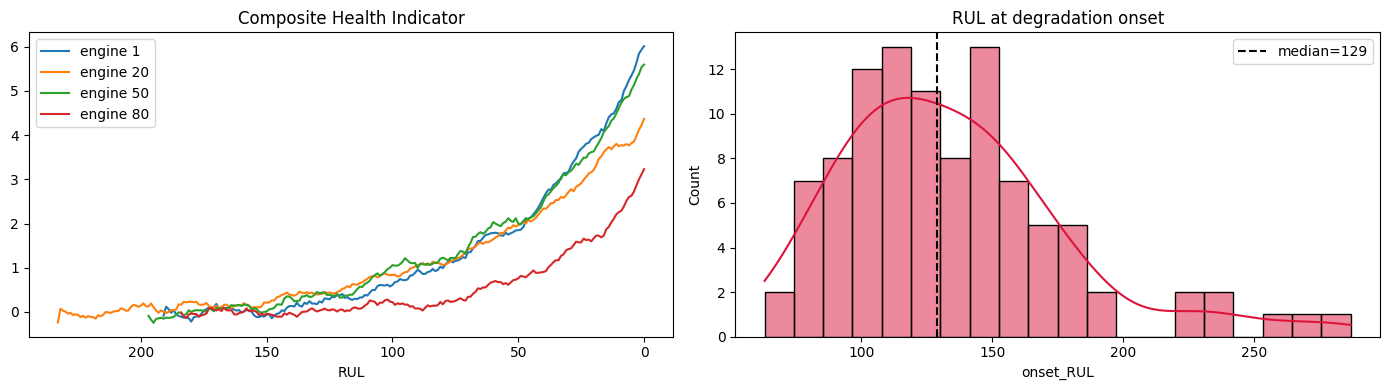

Detected engines: 100/100
Onset RUL: median 129, middle 50% of engines between 104 and 153
Median share of life used before onset: 35%


In [17]:
# --- Step 5: plots ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: health indicator vs RUL for 4 engines
for u in examples:
    rul_values, hi_values = examples[u]
    axes[0].plot(rul_values, hi_values, label=f"engine {u}")
axes[0].invert_xaxis()                     # failure (RUL 0) on the right
axes[0].set_xlabel("RUL")
axes[0].set_title("Composite Health Indicator")
axes[0].legend()

# Right: distribution of onset RUL over all engines
median_rul = onset_df["onset_RUL"].median()
sns.histplot(onset_df["onset_RUL"], bins=20, kde=True, ax=axes[1], color="crimson")
axes[1].axvline(median_rul, color="k", ls="--", label=f"median={median_rul:.0f}")
axes[1].set_title("RUL at degradation onset")
axes[1].legend()

plt.tight_layout()
plt.show()

# --- Step 6: printed summary ---
detected = len(onset_df)
total = train1["unit"].nunique()
q25 = onset_df["onset_RUL"].quantile(0.25)
q75 = onset_df["onset_RUL"].quantile(0.75)
print(f"Detected engines: {detected}/{total}")
print(f"Onset RUL: median {median_rul:.0f}, middle 50% of engines between {q25:.0f} and {q75:.0f}")

pct_used = 100 * (1 - onset_df["onset_RUL"] / onset_df["life"]).median()
print(f"Median share of life used before onset: {pct_used:.0f}%")

## 2.8 Degradation onset for all four datasets
Same idea as 2.7, but for FD002 and FD004 the sensors are first z-scored inside each operating condition (found with KMeans), otherwise the condition jumps would trigger a false onset.

In [18]:
# ===== 2.8 onset for FD001 to FD004 =====
def onset_analysis(fd, n_cond, corr_cut=0.5):
    df = train_data[fd].copy()       # copy, so train_data stays untouched

    # A: operating condition of every row
    if n_cond > 1:
        km = KMeans(n_clusters=n_cond, random_state=0, n_init=10)
        df["cond"] = km.fit_predict(df[["op1", "op2", "op3"]])
    else:
        df["cond"] = 0
    print(fd, "rows per condition:", df["cond"].value_counts().sort_index().tolist())

    # B: z-score every sensor inside its own condition
    grp = df.groupby("cond")[sensor_cols]
    df[sensor_cols] = (df[sensor_cols] - grp.transform("mean")) / (grp.transform("std") + 1e-9)

    # C: choose key sensors (Spearman with RUL, on the normalised data)
    good = [s for s in sensor_cols if df[s].std() > 1e-3]
    corr = df[good + ["RUL"]].corr(method="spearman")["RUL"].drop("RUL")
    key = corr[corr.abs() > corr_cut].index.tolist()
    print(fd, "key sensors:", key)

    # D: onset for every engine (make_hi and find_onset from 2.7)
    onset_list, examples = [], {}
    for u, g in df.groupby("unit"):
        hi = make_hi(g, key, corr)
        k = find_onset(hi)
        if k is not None:
            onset_list.append({"unit": u,
                               "onset_RUL": g["RUL"].iloc[k],
                               "life": len(g)})
        if u in [1, 20, 50, 80]:
            examples[u] = (g["RUL"].values, hi.values)

    return pd.DataFrame(onset_list), examples

# Run for all four
onset_results = {}
for fd, n_cond in [("FD001", 1), ("FD002", 6), ("FD003", 1), ("FD004", 6)]:
    onset_results[fd] = onset_analysis(fd, n_cond)

FD001 rows per condition: [20631]
FD001 key sensors: ['s2', 's3', 's4', 's7', 's8', 's11', 's12', 's13', 's15', 's17', 's20', 's21']
FD002 rows per condition: [13458, 8096, 8002, 8044, 8037, 8122]
FD002 key sensors: ['s2', 's3', 's4', 's11', 's15', 's17']
FD003 rows per condition: [24720]
FD003 key sensors: ['s2', 's3', 's4', 's8', 's9', 's11', 's13', 's17']
FD004 rows per condition: [15395, 9224, 9139, 9238, 9091, 9162]
FD004 key sensors: ['s2', 's3', 's4', 's8', 's9', 's11', 's13', 's17']


In [19]:
# summary table
rows = {}
for fd in onset_results:
    o = onset_results[fd][0]
    rows[fd] = {
        "detected": f"{len(o)}/{train_data[fd]['unit'].nunique()}",
        "median onset RUL": o["onset_RUL"].median(),
        "25%": o["onset_RUL"].quantile(0.25),
        "75%": o["onset_RUL"].quantile(0.75),
        "% life used at onset": round(100 * (1 - o["onset_RUL"] / o["life"]).median()),
    }
pd.DataFrame(rows).T

,detected,median onset RUL,25%,75%,% life used at onset
FD001,100/100,129.0,104.0,153.0,35
FD002,260/260,113.0,92.0,139.25,43
FD003,100/100,136.5,115.75,179.25,39
FD004,249/249,133.0,104.0,169.0,44


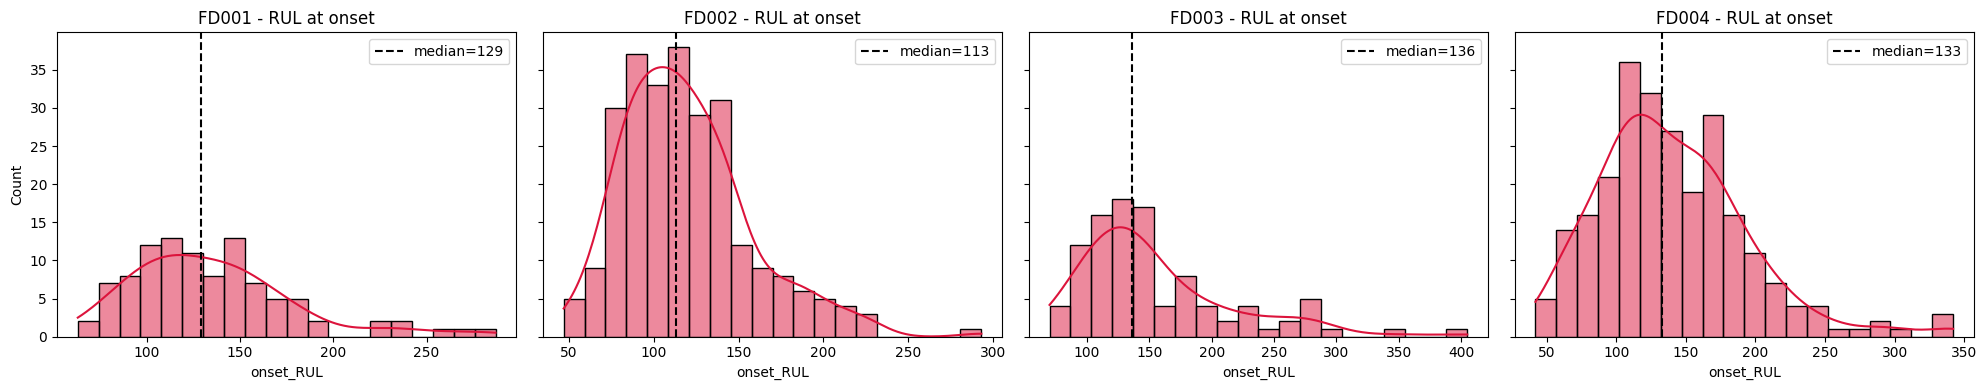

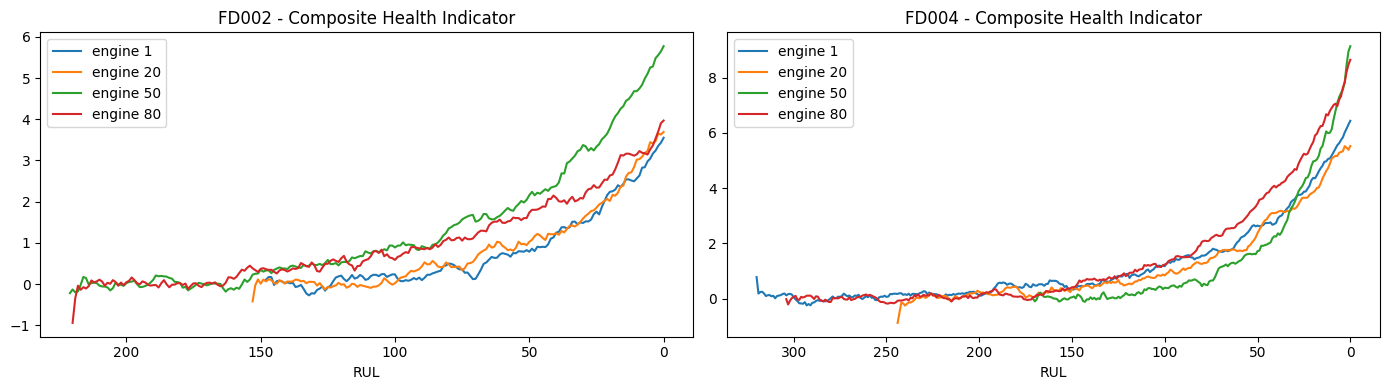

In [20]:
# histograms of onset RUL for all four
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, fd in zip(axes, onset_results):
    o = onset_results[fd][0]
    sns.histplot(o["onset_RUL"], bins=20, kde=True, ax=ax, color="crimson")
    ax.axvline(o["onset_RUL"].median(), color="k", ls="--",
               label=f"median={o['onset_RUL'].median():.0f}")
    ax.set_title(f"{fd} - RUL at onset")
    ax.legend()
plt.tight_layout()
plt.show()

# health indicator curves for FD002 and FD004
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, fd in zip(axes, ["FD002", "FD004"]):
    for u, (r, h) in onset_results[fd][1].items():
        ax.plot(r, h, label=f"engine {u}")
    ax.invert_xaxis()
    ax.set_title(f"{fd} - Composite Health Indicator")
    ax.set_xlabel("RUL")
    ax.legend()
plt.tight_layout()
plt.show()

## 2.9 Truncation analysis of the test set
How hard is the test set, and does it look like the training data?

- **Plot 1 (KDE):** distribution of the true RUL at the last test cycle.
- **Plot 2 (scatter):** one dot per test engine, observed cycles on x and final RUL on y.
- **Plot 3 (KDE):** distribution of how many cycles we observe for each test engine.

In [21]:
# ===== 2.9 test set truncation =====
last_rows = {}                                   # empty dictionary, one entry per dataset

for fd in FDS:
    last = test_data[fd].groupby("unit").tail(1) # keep ONLY the last row of every engine
    last_rows[fd] = last[["unit", "cycle", "RUL"]]
print(last_rows["FD001"].head())

for fd in FDS:
    t = last_rows[fd]
    print(fd,
          "| observed cycles: min", t["cycle"].min(), "median", t["cycle"].median(), "max", t["cycle"].max(),
          "| final RUL: min", t["RUL"].min(), "median", t["RUL"].median(), "max", t["RUL"].max())

     unit  cycle  RUL
30      1     31  112
79      2     49   98
205     3    126   69
311     4    106   82
409     5     98   91
FD001 | observed cycles: min 31 median 133.5 max 303 | final RUL: min 7 median 86.0 max 145
FD002 | observed cycles: min 21 median 132.0 max 367 | final RUL: min 6 median 80.0 max 194
FD003 | observed cycles: min 38 median 148.0 max 475 | final RUL: min 6 median 77.5 max 145
FD004 | observed cycles: min 19 median 153.5 max 486 | final RUL: min 6 median 88.0 max 195


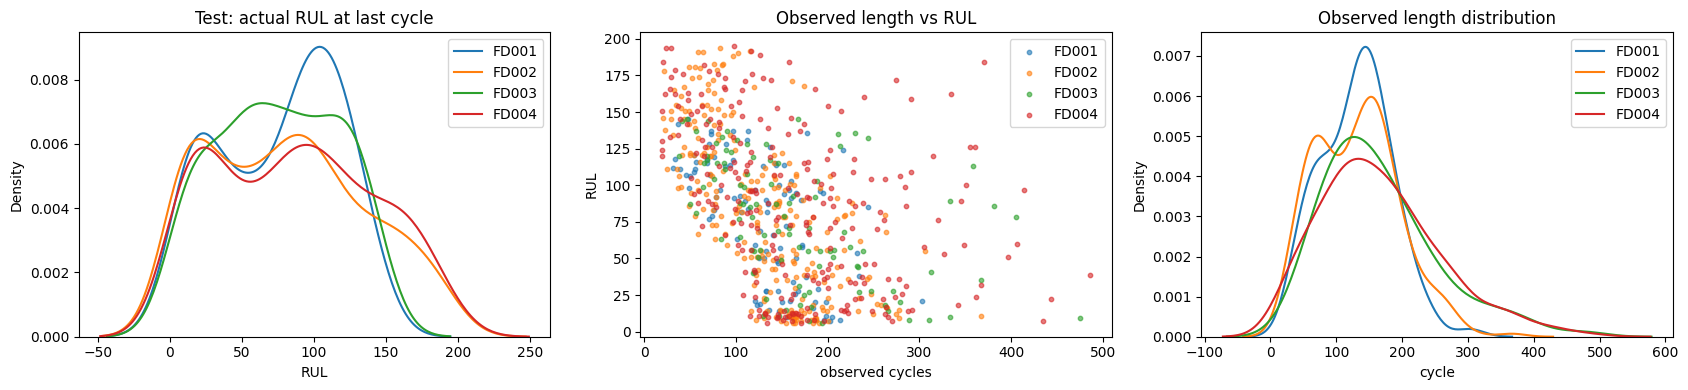

FD001: 11% of test engines have RUL > 125
FD002: 22% of test engines have RUL > 125
FD003: 15% of test engines have RUL > 125
FD004: 27% of test engines have RUL > 125
FD001: 0 test engines have fewer than 30 observed cycles
FD002: 6 test engines have fewer than 30 observed cycles
FD003: 0 test engines have fewer than 30 observed cycles
FD004: 11 test engines have fewer than 30 observed cycles


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))   # 1 row, 3 empty charts

for fd in FDS:                                    # draw all 4 datasets on every chart
    t = last_rows[fd]

    sns.kdeplot(t["RUL"], ax=axes[0], label=fd)                        # chart 1
    axes[1].scatter(t["cycle"], t["RUL"], s=10, alpha=0.6, label=fd)   # chart 2
    sns.kdeplot(t["cycle"], ax=axes[2], label=fd)                      # chart 3

axes[0].set_title("Test: actual RUL at last cycle")
axes[1].set_title("Observed length vs RUL")
axes[1].set_xlabel("observed cycles")
axes[1].set_ylabel("RUL")
axes[2].set_title("Observed length distribution")

for a in axes:
    a.legend()                                    # show dataset names in each chart

plt.tight_layout()
plt.show()

for fd in FDS:
    share = (last_rows[fd]["RUL"] > 125).mean()
    print(f"{fd}: {share:.0%} of test engines have RUL > 125")

window = 30
for fd in FDS:
    short = (last_rows[fd]["cycle"] < window).sum()
    print(f"{fd}: {short} test engines have fewer than {window} observed cycles")

# 3. Preprocessing

## 3.1 Target design: clipping the RUL at 125
Should the model be asked to tell RUL 300 from RUL 200, when the engine looks identical at both?

A flat sensor can't distinguish RUL 300 from RUL 200. If the target keeps falling in that phase, the model has to guess something that is not in the data, and it learns noise.

**The fix:** cap the target. Anything above 125 is treated as "healthy, 125". The target is then flat at 125 early on and falls linearly to 0 near failure. This shape is called a **piecewise-linear RUL**.

- 125 is a convention, not a law. Some papers use 130 or 150.
- The clipped model can't predict above 125, so the true test RUL is clipped as well when scoring.

In [23]:
# ===== 3.1 RUL clipping =====
CLIP = 125

for fd in FDS:
    train_data[fd]["RUL_clipped"] = train_data[fd]["RUL"].clip(upper=CLIP)   #.clip(upper=CLIP) replaces every value above 125 with 125 and leaves smaller values alone.
    test_data[fd]["RUL_clipped"]  = test_data[fd]["RUL"].clip(upper=CLIP)    # test is clipped too, for scoring later
#The result goes into a new column, so RUL is untouched.

display(train_data["FD001"][["unit", "cycle", "RUL", "RUL_clipped"]].head())
display(train_data["FD001"][["RUL", "RUL_clipped"]].describe())

,unit,cycle,RUL,RUL_clipped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


,RUL,RUL_clipped
count,20631.000000,20631.000000
mean,107.807862,86.829286
std,68.880990,41.673699
min,0.000000,0.000000
25%,51.000000,51.000000
50%,103.000000,103.000000
75%,155.000000,125.000000
max,361.000000,125.000000


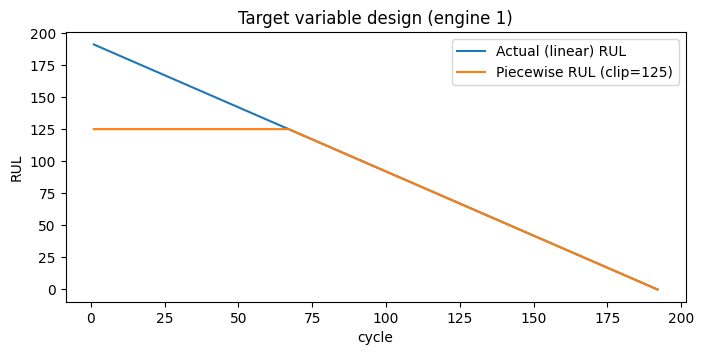

In [24]:
# plot of RUL vs RUL_clipped for engine 1
train = train_data["FD001"]
g = train[train["unit"] == 1]            # only engine 1

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(g["cycle"], g["RUL"], label="Actual (linear) RUL")
ax.plot(g["cycle"], g["RUL_clipped"], label=f"Piecewise RUL (clip={CLIP})")
ax.set_xlabel("cycle")
ax.set_ylabel("RUL")
ax.set_title("Target variable design (engine 1)")
ax.legend()
plt.show()

## 3.2 Operating condition normalization
**Question:** How do we stop the flight settings from hiding the wear signal?

In 2.3 we saw that FD002 and FD004 jump between 6 flight conditions, and each condition shifts every sensor to a different level. The fix is to z-score each sensor **inside its own condition**. After that, "0" means "average for this condition", and what is left is mostly wear plus noise.

Steps:
1. **Cluster** the settings (op1, op2, op3) with KMeans to give each row a condition label. FD001/FD003 use 1 cluster and FD002/FD004 use 6.
2. **Z-score** each sensor within its condition, using the **training** mean and std.
3. **Drop** sensors that are still constant afterwards.

**Leakage rule:** the KMeans centres and the mean/std of each condition are learned from train only, and then the same values are applied to the test rows.

In [25]:
# ===== 3.2 condition-wise normalization =====
N_COND = {"FD001": 1, "FD002": 6, "FD003": 1, "FD004": 6}

def preprocess(fd):
    # copy so the original train_data / test_data stay untouched
    tr = train_data[fd].copy()          # it makes a independent copy and creates a table
    te = test_data[fd].copy()
    n = N_COND[fd]

    # FIX: make sure every sensor column is float, so z-scores can be stored
    tr[sensor_cols] = tr[sensor_cols].astype(float)
    te[sensor_cols] = te[sensor_cols].astype(float)

    # Step 1: learn the conditions on TRAIN, then label both train and test
    km = KMeans(n_clusters=n, n_init=10, random_state=42)       #n cluster by closeness and 10 starting guesses
    km.fit(tr[op_cols])         #only training data
    tr["cond"] = km.predict(tr[op_cols])            #predict gives each row the label of its nearest centre. Test rows are labelled with the train centres, which is the leakage-safe way. A new column cond (0 to 5) is added.
    te["cond"] = km.predict(te[op_cols])

    # Step 2: mean and std of every sensor inside each condition (TRAIN only)
    mu = tr.groupby("cond")[sensor_cols].mean()             #Tables of size (conditions x 21 sensors) holding the mean and std of each sensor in each condition. For FD002 that is 6 rows x 21 columns.
    sd = tr.groupby("cond")[sensor_cols].std()
    sd = sd.where(sd > 1e-8, 1.0)          # a std of 0 would divide by zero, so use 1
    # where(cond, other) keeps values where the condition is True and replaces the rest with other.

    # Step 3: z-score each condition separately
    for c in range(n):
        m_tr = tr["cond"] == c      #select rows in train where the condition is c
        m_te = te["cond"] == c
        tr.loc[m_tr, sensor_cols] = (tr.loc[m_tr, sensor_cols] - mu.loc[c]) / sd.loc[c]     #mu.loc[c] is that condition's 21 means. Subtracting it from the rows subtracts each sensor's own mean, and dividing by sd.loc[c] does the std part. That is the z-score from earlier.
        te.loc[m_te, sensor_cols] = (te.loc[m_te, sensor_cols] - mu.loc[c]) / sd.loc[c]

    # Step 4: keep only sensors that still vary after normalization
    keep = [s for s in sensor_cols if tr[s].var() > 0.1]

    return tr, te, keep, km

train_prep, test_prep, keep_sensors, kmeans_models = {}, {}, {}, {}
for fd in FDS:
    train_prep[fd], test_prep[fd], keep_sensors[fd], kmeans_models[fd] = preprocess(fd)
    print(f"{fd}: {len(keep_sensors[fd])} sensors retained ->", keep_sensors[fd])

FD001: 15 sensors retained -> ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
FD002: 17 sensors retained -> ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's20', 's21']
FD003: 16 sensors retained -> ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
FD004: 17 sensors retained -> ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's20', 's21']


**Raw vs normalized s11 for engine 1 of FD002.** Left: the line jumps between 6 bands as the engine changes flight condition, so the wear can't be seen. Right: the bands are gone and the slow upward drift toward failure shows. This is a visual proof that the normalization works.

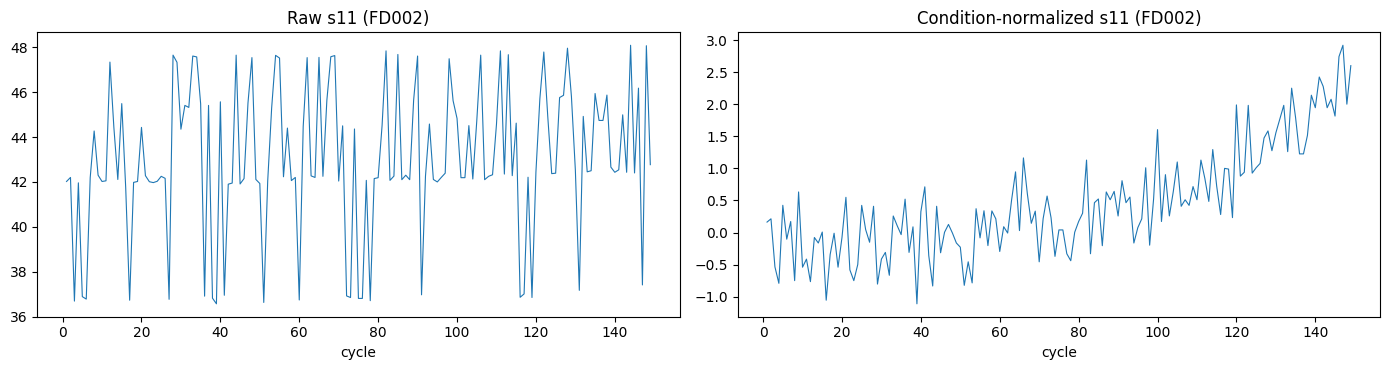

In [26]:
# ===== 3.2 check: raw vs normalized =====
raw2  = train_data["FD002"]
norm2 = train_prep["FD002"]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
titles = ["Raw s11 (FD002)", "Condition-normalized s11 (FD002)"]

for ax, df, t in zip(axes, [raw2, norm2], titles):
    g = df[df["unit"] == 1]                      # engine 1 only
    ax.plot(g["cycle"], g["s11"], lw=0.8)
    ax.set_title(t)
    ax.set_xlabel("cycle")

plt.tight_layout()
plt.show()

In [27]:
# train: mean should be ~0 and std ~1 in every condition
display(train_prep["FD002"].groupby("cond")["s11"].agg(["mean", "std"]).round(2))

# test: close to, but not exactly, 0 and 1
display(test_prep["FD002"].groupby("cond")["s11"].agg(["mean", "std"]).round(2))

# how many rows per condition (expect 6 groups)
display(train_prep["FD002"]["cond"].value_counts().sort_index())

,mean,std
cond,,
0,0.0,1.0
1,-0.0,1.0
2,-0.0,1.0
3,-0.0,1.0
4,-0.0,1.0
5,0.0,1.0


,mean,std
cond,,
0,-0.33,0.77
1,-0.34,0.79
2,-0.38,0.80
3,-0.33,0.78
4,-0.35,0.76
5,-0.32,0.79


cond
0    13458
1     8122
2     8002
3     8044
4     8096
5     8037
Name: count, dtype: int64

s10 and s16 were constant in FD001 but survive in some other datasets. Check whether they carry any signal:

In [28]:
for fd in ["FD002", "FD003", "FD004"]:
    df = train_prep[fd]
    for s in ["s10", "s16"]:
        if s in keep_sensors[fd]:
            print(fd, s, "Spearman with RUL:", round(df[s].corr(df["RUL"], method="spearman"), 3))

FD002 s10 Spearman with RUL: 0.072
FD002 s16 Spearman with RUL: -0.191
FD003 s10 Spearman with RUL: -0.431
FD004 s10 Spearman with RUL: -0.224
FD004 s16 Spearman with RUL: -0.102


- s10 in FD003 (about -0.43) is a real signal. FD003 has the extra fan fault, so this sensor (engine pressure ratio) comes alive there.
- s10 in FD002 and s16 in FD004 are near 0, mostly noise.
- I kept all of them. Tree models can ignore useless columns, and removing sensors by hand is a decision I would have to defend.

## 3.3 PCA-based health indicator (check of the normalization)
**Question:** Can we squeeze 15 to 17 sensors into a single number that tracks degradation?

PCA finds the one direction in which the sensors vary the most (PC1). If the normalization worked, PC1 should show a smooth trend toward failure, even in FD004 with 6 conditions. The sign of PC1 is arbitrary, so only the trend matters, not up or down.

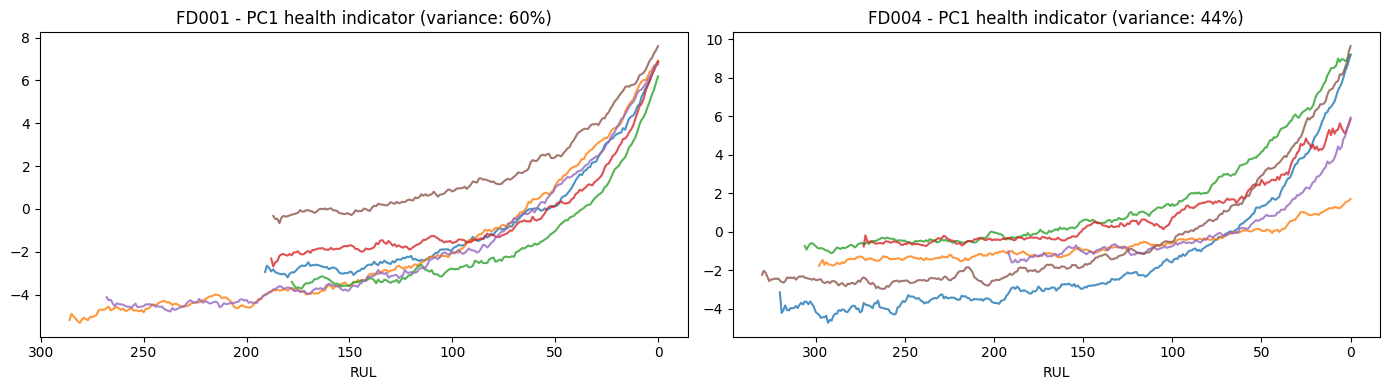

In [29]:
# ===== 3.3 PCA health indicator =====
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, fd in zip(axes, ["FD001", "FD004"]):
    tr = train_prep[fd]                       # normalized training table
    keep = keep_sensors[fd]                   # sensors that survived 3.2

    pca = PCA(n_components=3)           #Creates a PCA that keeps 3 directions, and learns them from the sensor columns only. RUL is not used, so there is no leakage of the target.
    pca.fit(tr[keep])                         # learn the directions from sensors only

    pc1 = pca.transform(tr[keep])[:, 0]       # first column = PC1 for every row         transform turns each row's 15 sensor values into 3 new numbers (PC1, PC2, PC3). [:, 0] keeps all rows but only the first column, PC1.
    tmp = tr.copy()                         #Copies the table and adds PC1 as a column, so train_prep isn't changed.
    tmp["PC1"] = pc1                          # attach it to the table

    for u in sorted(tmp["unit"].unique())[:6]:       # first 6 engines only
        g = tmp[tmp["unit"] == u]
        smooth = g["PC1"].rolling(10, min_periods=1).mean()         #rolling Smooths the noise, same as before.
        ax.plot(g["RUL"], smooth, alpha=0.8)

    ax.invert_xaxis()
    ax.set_xlabel("RUL")
    share = 100 * pca.explained_variance_ratio_[0]
    ax.set_title(f"{fd} - PC1 health indicator (variance: {share:.0f}%)")

plt.tight_layout()
plt.show()

After normalization, a single PCA direction gives a consistent degradation path across engines, even in FD004 with six conditions, confirming that the preprocessing worked.

# 4. Evaluation Metric
**Question:** How do we measure whether a model's RUL predictions are good?

Every model needs the same scoring, otherwise we can't compare them. So the metrics are defined once, before any model exists.

- **RMSE:** root mean squared error (big errors are punished more).
- **MAE:** mean absolute error (average miss in cycles).
- **R²:** how much of the variation in RUL the model explains (1 = perfect).
- **NASA Score:** predicting failure too late is dangerous (the engine fails before you service it). Predicting too early only wastes some engine life. So late errors cost more.

In [30]:
# ===== 4. metrics =====

# 1) NASA score
def nasa_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    d = y_pred - y_true                       # error of every engine

    early = d < 0                             # True where prediction is too early
    penalty = np.zeros(len(d))                # empty array to fill
    penalty[early]  = np.exp(-d[early] / 13) - 1      # early formula
    penalty[~early] = np.exp(d[~early] / 10) - 1      # late formula (~ means "not")
    return float(penalty.sum())               # add up over engines

# 2) All four metrics together
def evaluate(y_true, y_pred, upper=CLIP):
    y_pred = np.clip(y_pred, 0, upper)        # RUL can't be below 0 or above the cap
    return {"RMSE":  np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE":   mean_absolute_error(y_true, y_pred),
            "R2":    r2_score(y_true, y_pred),
            "Score": nasa_score(y_true, y_pred)}

# 3) Store and print results for every model we try
results = []        # list of result rows
preds = {}          # stores predictions per (dataset, model)

def log(fd, name, y_true, y_pred):
    m = evaluate(y_true, y_pred)
    results.append({"Dataset": fd, "Model": name, **m})
    preds[(fd, name)] = np.clip(y_pred, 0, CLIP)
    print(f"{fd} | {name:<14} RMSE={m['RMSE']:.2f}  MAE={m['MAE']:.2f}  R2={m['R2']:.3f}  Score={m['Score']:.0f}")

In [31]:
# true answer for each test engine = clipped RUL at its LAST observed cycle
y_test_true = {}
for fd in FDS:
    last = test_data[fd].groupby("unit").tail(1).sort_values("unit")
    y_test_true[fd] = last["RUL_clipped"].values      # clipped at 125

# 5. Feature Engineering
**Question:** A model that sees one row at a time is judging one noisy reading. How do we give it memory of the engine's recent history?

We add columns that summarize the past of each row. This is the main reason classical ML models can do well on this dataset.

| Feature | Question it answers |
|---|---|
| `_m` rolling mean | What is the sensor's average over the last 10 cycles? (removes noise) |
| `_sd` rolling std | How jumpy was the sensor lately? |
| `_ewm` exponential average | Like the rolling mean, but recent cycles count more |
| `_slope` | How fast is the sensor changing? (x_t - x_{t-10}) / 10 |
| `_dev` deviation from baseline | How far is the sensor from this engine's own first 15 cycles? |

Three feature sets (used later in the ablation study):
- `raw` = normalized sensors + cycle
- `roll` = raw + rolling mean + rolling std
- `full` = roll + EWMA + slope + deviation

All features only use the current and earlier cycles, never later ones (causal), because in real use we can't see the future.

In [32]:
# ===== 5.1 build_features (one engine at a time) =====
def build_features(df, feats, fset="full", w=10):
    # df    = a preprocessed table (train_prep[fd] or test_prep[fd])
    # feats = the sensor columns to use (keep_sensors[fd])
    # fset  = "raw", "roll" or "full"
    # w     = window length for rolling features

    # sort so rows are in time order inside each engine; fresh row numbers 0,1,2,...
    df = df.sort_values(["unit", "cycle"]).reset_index(drop=True)

    pieces = []                                   # one finished feature table per engine

    for u, g in df.groupby("unit"):               # g = the rows of ONE engine
        sens = g[feats]                           # that engine's sensor columns
        parts = [sens]                            # always start with the raw sensors

        if fset in ("roll", "full"):
            roll = sens.rolling(w, min_periods=1)
            parts.append(roll.mean().add_suffix("_m"))               # rolling mean
            parts.append(roll.std().fillna(0).add_suffix("_sd"))     # rolling std

        if fset == "full":
            parts.append(sens.ewm(span=w).mean().add_suffix("_ewm"))      # EWMA
            slope = (sens - sens.shift(w)) / w                            # change over w cycles
            parts.append(slope.fillna(0).add_suffix("_slope"))
            baseline = sens.iloc[:15].mean()                              # engine's first-15-cycle mean
            parts.append((sens - baseline).add_suffix("_dev"))            # deviation from it

        X_u = pd.concat(parts, axis=1)            # glue the pieces side by side
        X_u["cycle"] = g["cycle"]
        pieces.append(X_u)

    X = pd.concat(pieces)                          # stack all engines (same row order as df)
    return df, X

In [33]:
# ===== 5.2 tabular (build everything for one dataset) =====
def tabular(fd, fset="full", clip=CLIP, w=10):
    tr, Xtr = build_features(train_prep[fd], keep_sensors[fd], fset, w)
    te, Xte = build_features(test_prep[fd],  keep_sensors[fd], fset, w)

    # official test scoring uses ONLY the last row of each test engine
    last_idx = te.groupby("unit").tail(1).index

    return dict(
        Xtr=Xtr,
        ytr=tr["RUL"].clip(upper=clip).values,      # clipped training target
        groups=tr["unit"].values,                    # engine id, used later to split by engine
        Xte_last=Xte.loc[last_idx],                  # one row per test engine
        yte=te.loc[last_idx, "RUL_clipped"].values,  # true clipped RUL of those rows
        Xte_all=Xte,                                 # every test row (for extra plots)
        yte_all=te["RUL"].values,
        te=te,
    )

tab = {fd: tabular(fd) for fd in FDS}
print({fd: tab[fd]["Xtr"].shape for fd in FDS})

{'FD001': (20631, 91), 'FD002': (53759, 103), 'FD003': (24720, 97), 'FD004': (61249, 103)}


In [34]:
# ===== 5.3 sanity checks =====
# 1) no missing values
for fd in FDS:
    print(fd, "NaN in train features:", tab[fd]["Xtr"].isna().sum().sum(),
          "| NaN in test features:", tab[fd]["Xte_last"].isna().sum().sum())

# 2) test order matches the answer vector from section 4
for fd in FDS:
    print(fd, "same as y_test_true:", np.array_equal(tab[fd]["yte"], y_test_true[fd]))

# 3) look at a few new columns for engine 1
tab["FD001"]["Xtr"][["s11", "s11_m", "s11_sd", "s11_ewm", "s11_slope", "s11_dev"]].head(12)

FD001 NaN in train features: 0 | NaN in test features: 0
FD002 NaN in train features: 0 | NaN in test features: 0
FD003 NaN in train features: 0 | NaN in test features: 0
FD004 NaN in train features: 0 | NaN in test features: 0
FD001 same as y_test_true: True
FD002 same as y_test_true: True
FD003 same as y_test_true: True
FD004 same as y_test_true: True


,s11,s11_m,s11_sd,s11_ewm,s11_slope,s11_dev
0,-0.266460,-0.266460,0.000000,-0.266460,0.000000,0.718866
1,-0.191578,-0.229019,0.052949,-0.225275,0.000000,0.793748
2,-1.015279,-0.491106,0.455489,-0.542851,0.000000,-0.029953
3,-1.539452,-0.753192,0.642706,-0.871187,0.000000,-0.554126
4,-0.977838,-0.798121,0.565594,-0.901803,0.000000,0.007488
5,-1.427129,-0.902956,0.567326,-1.038249,0.000000,-0.441803
6,-0.678310,-0.870864,0.524809,-0.951518,0.000000,0.307016
7,-1.127601,-0.902956,0.494285,-0.991578,0.000000,-0.142276
8,-0.940397,-0.907116,0.462530,-0.980443,0.000000,0.044929
9,-1.913861,-1.007791,0.539923,-1.176513,0.000000,-0.928535


# 6. ML Models
## 6.1 Ridge, Random Forest, Extra Trees, Hist Gradient Boosting
Each model is trained on the full training set of one dataset and tested on the last row of every test engine.

In [35]:
# ===== 6.1 train and test the 4 models =====
SEED = 42
QUICK = False        # True = fewer trees, faster run, for a quick test

def make_models():
    n_trees = 80 if QUICK else 300
    n_iter  = 300 if QUICK else 500
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),

        "RandomForest": RandomForestRegressor(
            n_estimators=n_trees, max_depth=14, min_samples_leaf=5,
            max_features=0.4, n_jobs=-1, random_state=SEED),

        "ExtraTrees": ExtraTreesRegressor(
            n_estimators=n_trees, max_depth=16, min_samples_leaf=5,
            max_features=0.5, n_jobs=-1, random_state=SEED),

        "HistGB": HistGradientBoostingRegressor(
            max_iter=n_iter, learning_rate=0.05, max_depth=6,
            l2_regularization=1.0, random_state=SEED),
    }

fitted_ml = {}                                     # keeps every trained model

for fd in FDS:
    d = tab[fd]                                    # features and targets of this dataset
    for name, model in make_models().items():
        model.fit(d["Xtr"], d["ytr"])              # learn from TRAIN only
        fitted_ml[(fd, name)] = model              # save it for later use
        pred = model.predict(d["Xte_last"])        # predict last row of each test engine
        log(fd, name, d["yte"], pred)              # score and print (section 4)
    print()                                        # blank line between datasets

FD001 | Ridge          RMSE=16.25  MAE=13.15  R2=0.836  Score=410
FD001 | RandomForest   RMSE=12.15  MAE=8.93  R2=0.908  Score=209
FD001 | ExtraTrees     RMSE=12.19  MAE=9.02  R2=0.907  Score=211
FD001 | HistGB         RMSE=12.43  MAE=8.54  R2=0.904  Score=211

FD002 | Ridge          RMSE=15.55  MAE=12.59  R2=0.869  Score=1082
FD002 | RandomForest   RMSE=12.88  MAE=9.34  R2=0.910  Score=776
FD002 | ExtraTrees     RMSE=12.76  MAE=9.42  R2=0.912  Score=717
FD002 | HistGB         RMSE=11.33  MAE=7.94  R2=0.930  Score=604

FD003 | Ridge          RMSE=15.89  MAE=12.83  R2=0.835  Score=490
FD003 | RandomForest   RMSE=12.90  MAE=9.03  R2=0.891  Score=338
FD003 | ExtraTrees     RMSE=13.65  MAE=9.62  R2=0.879  Score=396
FD003 | HistGB         RMSE=11.93  MAE=8.30  R2=0.907  Score=291

FD004 | Ridge          RMSE=16.79  MAE=13.18  R2=0.847  Score=1437
FD004 | RandomForest   RMSE=14.27  MAE=10.04  R2=0.890  Score=1029
FD004 | ExtraTrees     RMSE=14.23  MAE=10.23  R2=0.890  Score=1010
FD004 | Hist

## 6.2 Feature set ablation study
**Question:** Did the extra features (rolling, EWMA, slope, deviation) really help, or did we add 75 columns for nothing?

An ablation study adds one ingredient at a time while everything else stays fixed. The model is fixed (HistGB) and only the feature set changes (`raw` -> `roll` -> `full`). FD001 (easy: one condition, one fault) and FD004 (hard: six conditions, two faults) are used.

In [36]:
# ===== 6.2 ablation: raw vs roll vs full =====
abl_rows = []

for fd in ["FD001", "FD004"]:                     # easy and hard dataset
    for fset in ["raw", "roll", "full"]:          # three feature sets
        d = tabular(fd, fset)                     # rebuild features for this set

        model = HistGradientBoostingRegressor(
            max_iter=300, learning_rate=0.05, random_state=SEED)
        model.fit(d["Xtr"], d["ytr"])             # train on TRAIN only

        pred = model.predict(d["Xte_last"])       # last row of each test engine
        scores = evaluate(d["yte"], pred)         # RMSE, MAE, R2, Score

        abl_rows.append({"Dataset": fd,
                         "Feature Set": fset,
                         "n_features": d["Xtr"].shape[1],
                         **scores})

abl_df = pd.DataFrame(abl_rows)
abl_df.round(3)

,Dataset,Feature Set,n_features,RMSE,MAE,R2,Score
0,FD001,raw,16,17.960,13.393,0.799,613.663
1,FD001,roll,46,18.223,13.075,0.793,789.686
2,FD001,full,91,12.447,8.435,0.904,211.413
3,FD004,raw,18,17.857,12.532,0.827,2008.714
4,FD004,roll,52,17.007,11.886,0.843,1621.340
5,FD004,full,103,12.485,8.455,0.916,732.673


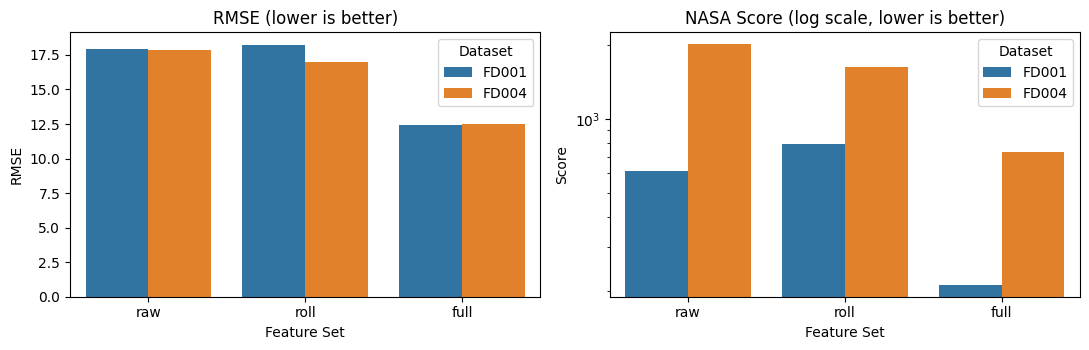

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

sns.barplot(data=abl_df, x="Feature Set", y="RMSE", hue="Dataset", ax=axes[0])
axes[0].set_title("RMSE (lower is better)")

sns.barplot(data=abl_df, x="Feature Set", y="Score", hue="Dataset", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("NASA Score (log scale, lower is better)")

plt.tight_layout()
plt.show()

## 6.3 Predicted RUL over the whole life of a test engine
**Question:** At every cycle of a test engine, how does the predicted RUL compare with the truth?

The final score uses only one row per engine. This plot shows the whole curve, so we can see where the model is wrong: noisy early, accurate near failure, or late. The red dotted line at 30 cycles is an example maintenance alert level.

### HistGB only (lowest error)

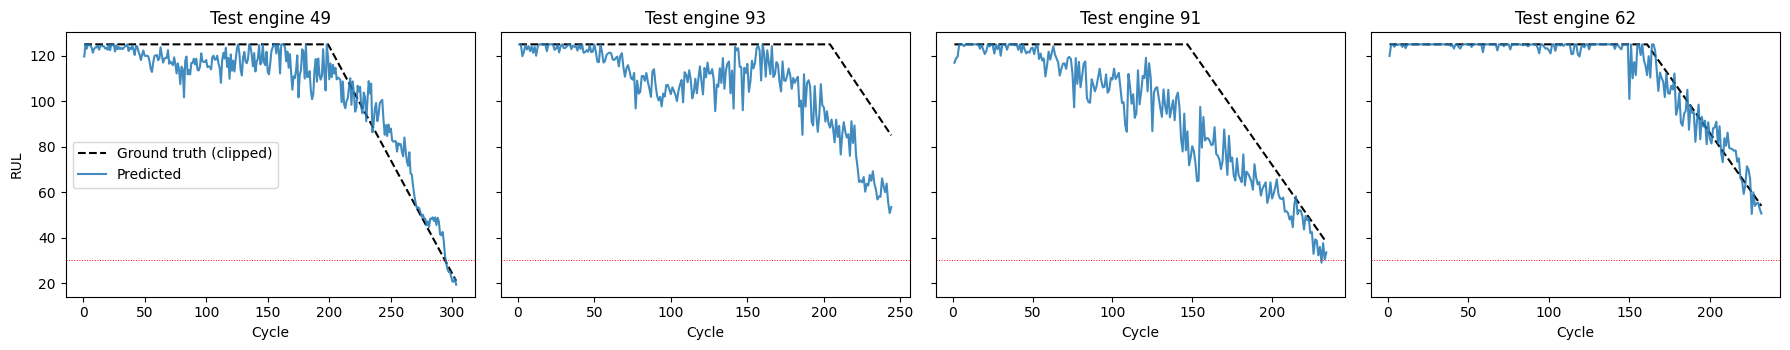

In [38]:
# ===== 6.3a HistGB trajectory on the 4 longest test engines (FD001) =====
fd = "FD001"
model_name = "HistGB"
ALERT = 30

d = tab[fd]
te = d["te"]
p_all = np.clip(fitted_ml[(fd, model_name)].predict(d["Xte_all"]), 0, CLIP)

traj = pd.DataFrame({
    "unit":  te["unit"].values,
    "cycle": te["cycle"].values,
    "true":  np.minimum(te["RUL"].values, CLIP),   # clipped truth
    "pred":  p_all,
})

longest = traj.groupby("unit").size().nlargest(4).index     # 4 engines with most history

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, u in zip(axes, longest):
    g = traj[traj["unit"] == u]
    ax.plot(g["cycle"], g["true"], "k--", label="Ground truth (clipped)")
    ax.plot(g["cycle"], g["pred"], label="Predicted", alpha=0.85)
    ax.axhline(ALERT, color="red", lw=0.7, ls=":")
    ax.set_title(f"Test engine {u}")
    ax.set_xlabel("Cycle")
axes[0].legend()
axes[0].set_ylabel("RUL")
plt.tight_layout(); plt.show()

### All four models in a single graph

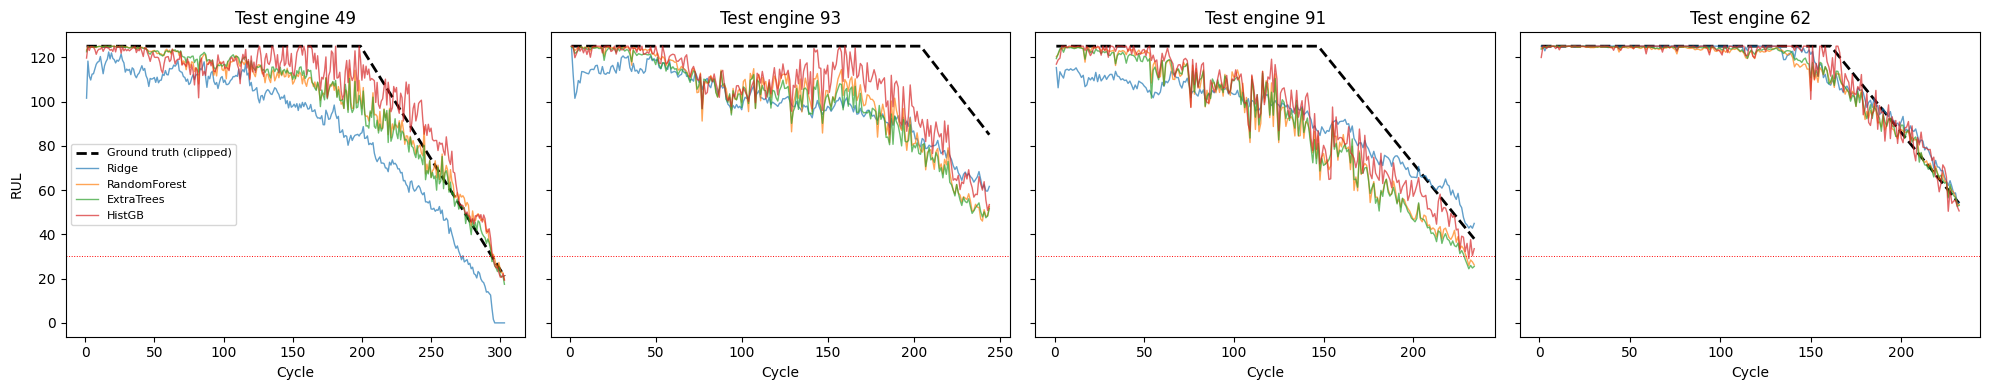

In [39]:
# ===== 6.3b all models on the same engines =====
model_names = ["Ridge", "RandomForest", "ExtraTrees", "HistGB"]

# one prediction column per model, for EVERY test row
for name in model_names:
    traj[name] = np.clip(fitted_ml[(fd, name)].predict(d["Xte_all"]), 0, CLIP)

fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
for ax, u in zip(axes, longest):
    g = traj[traj["unit"] == u]
    ax.plot(g["cycle"], g["true"], "k--", lw=2, label="Ground truth (clipped)")
    for name in model_names:
        ax.plot(g["cycle"], g[name], alpha=0.7, lw=1, label=name)
    ax.axhline(ALERT, color="red", lw=0.7, ls=":")
    ax.set_title(f"Test engine {u}")
    ax.set_xlabel("Cycle")
axes[0].set_ylabel("RUL")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 7. Error Comparison
All 16 results (4 datasets x 4 models) in one table.

In [40]:
# ===== 7.1 results table =====
res = pd.DataFrame(results)
print(res.shape)                       # expect (16, 6): 4 datasets x 4 models
print(res["Model"].unique())

(16, 6)
['Ridge' 'RandomForest' 'ExtraTrees' 'HistGB']


In [41]:
# ===== 7.2 one coloured table per metric + ranking =====
ORDER = ["Ridge", "RandomForest", "ExtraTrees", "HistGB"]

for metric in ["RMSE", "MAE", "R2", "Score"]:
    t = res.pivot(index="Model", columns="Dataset", values=metric).reindex(ORDER)
    t["mean"] = t.mean(axis=1)

    cmap = "RdYlGn" if metric == "R2" else "RdYlGn_r"     # green = good
    decimals = 0 if metric == "Score" else 2

    display(t.round(decimals)
             .style.background_gradient(cmap=cmap, axis=0)
             .set_caption(metric))

rank = res.pivot(index="Model", columns="Dataset", values="RMSE").rank()
rank["mean rank"] = rank.mean(axis=1)
display(rank.sort_values("mean rank")
            .round(1)
            .style.background_gradient(cmap="RdYlGn_r")
            .set_caption("Rank by RMSE (1 = Best)"))

Dataset,FD001,FD002,FD003,FD004,mean
Model,,,,,
Ridge,16.250000,15.550000,15.890000,16.790000,16.120000
RandomForest,12.150000,12.880000,12.900000,14.270000,13.050000
ExtraTrees,12.190000,12.760000,13.650000,14.230000,13.210000
HistGB,12.430000,11.330000,11.930000,12.140000,11.960000


Dataset,FD001,FD002,FD003,FD004,mean
Model,,,,,
Ridge,13.150000,12.590000,12.830000,13.180000,12.940000
RandomForest,8.930000,9.340000,9.030000,10.040000,9.330000
ExtraTrees,9.020000,9.420000,9.620000,10.230000,9.570000
HistGB,8.540000,7.940000,8.300000,8.360000,8.280000


Dataset,FD001,FD002,FD003,FD004,mean
Model,,,,,
Ridge,0.840000,0.870000,0.840000,0.850000,0.850000
RandomForest,0.910000,0.910000,0.890000,0.890000,0.900000
ExtraTrees,0.910000,0.910000,0.880000,0.890000,0.900000
HistGB,0.900000,0.930000,0.910000,0.920000,0.920000


Dataset,FD001,FD002,FD003,FD004,mean
Model,,,,,
Ridge,410.000000,1082.000000,490.000000,1437.000000,855.000000
RandomForest,209.000000,776.000000,338.000000,1029.000000,588.000000
ExtraTrees,211.000000,717.000000,396.000000,1010.000000,583.000000
HistGB,211.000000,604.000000,291.000000,731.000000,459.000000


Dataset,FD001,FD002,FD003,FD004,mean rank
Model,,,,,
HistGB,3.000000,1.000000,1.000000,1.000000,1.500000
ExtraTrees,2.000000,2.000000,3.000000,2.000000,2.200000
RandomForest,1.000000,3.000000,2.000000,3.000000,2.200000
Ridge,4.000000,4.000000,4.000000,4.000000,4.000000


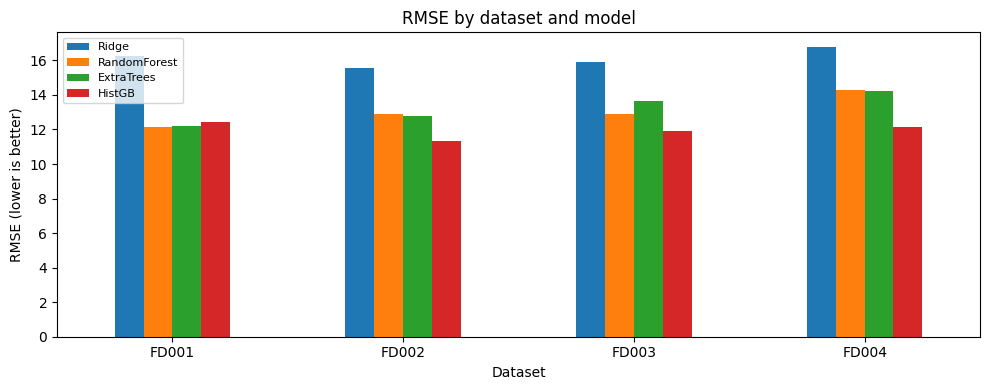

In [42]:
# ===== 7.3 RMSE bar chart =====
piv = res.pivot(index="Dataset", columns="Model", values="RMSE")[ORDER]
piv.plot.bar(figsize=(10, 4))
plt.ylabel("RMSE (lower is better)")
plt.title("RMSE by dataset and model")
plt.xticks(rotation=0)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 8. Conclusion
- The data had no missing values or duplicates. The main problems were constant sensors, noise, and (in FD002/FD004) six operating conditions that hide the wear signal.
- Clipping the RUL at 125, z-scoring each sensor inside its operating condition, and adding rolling/trend features were the three steps that made the models work.
- The ablation study shows the `full` feature set clearly beats only raw sensors on both FD001 and FD004.
- Hist Gradient Boosting gave the lowest error on most datasets. Ridge (a straight-line model) was the weakest, because the link between sensors and RUL is not linear.